In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from rdkit import Chem
from rdkit.Chem import Draw
from matplotlib.offsetbox import OffsetImage, AnnotationBbox

In [ ]:
df = pd.read_csv('./AHFEs_errors.csv',index_col= 0)


,exp(kcal/mol),MM (kcal/mol),ML_ref(kcal/mol),ML_ME(kcal/mol),ML_enhancedME (kcal/mol)
mol_repeat,,,,,
242480_1,-11.85,-13.97,-16.87,-14.82,-12.27
242480_2,-11.85,-14.06,-16.87,-14.92,-12.35
242480_3,-11.85,-13.97,-16.87,-14.84,-12.27
1396156_1,-5.22,-0.99,-1.51,-0.76,-3.07
1396156_2,-5.22,-0.98,-1.51,-0.77,-3.06
1396156_3,-5.22,-0.90,-1.51,-0.69,-2.99
2725802_1,-9.80,-6.65,-6.88,-6.58,-7.99
2725802_2,-9.80,-6.66,-6.88,-6.58,-7.97
2725802_3,-9.80,-6.65,-6.88,-6.56,-7.96


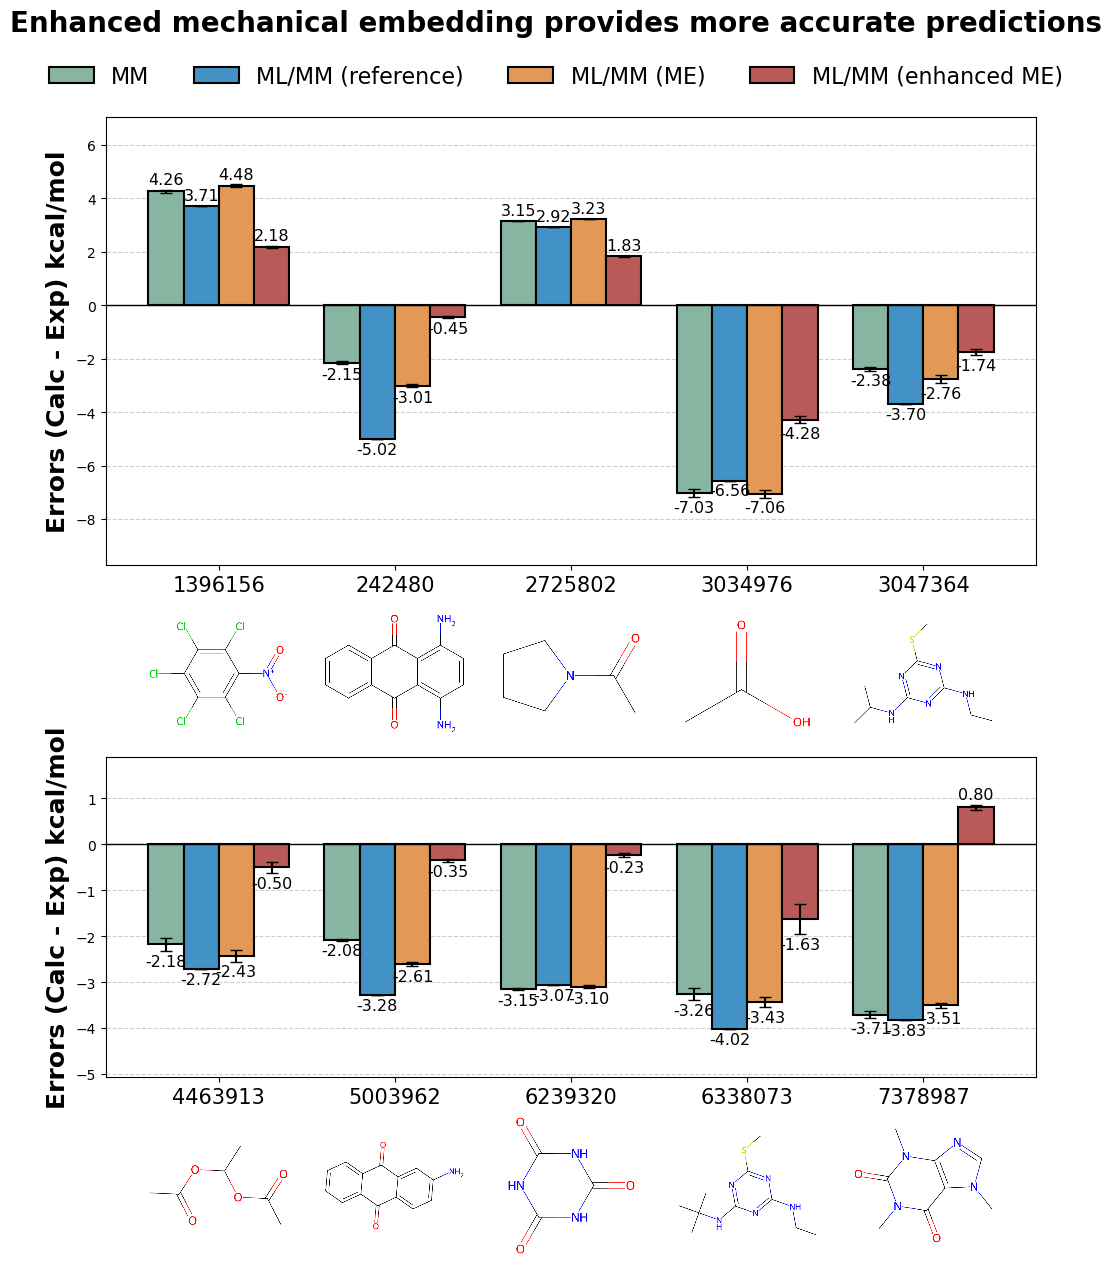

In [ ]:

exp_col = 'exp(kcal/mol)'
methods = ['MM (kcal/mol)', 'ML_ref(kcal/mol)', 'ML_ME(kcal/mol)', 'ML_enhancedME (kcal/mol)']
short_names = ['MM', 'ML_ref', 'ML_ME', 'ML_enhancedME']

df['mol_id'] = df.index.astype(str).map(lambda x: x.split('_')[0])

error_cols = []
for col, short_name in zip(methods, short_names):
    err_col_name = f'{short_name}_err'
    df[err_col_name] = df[col] - df[exp_col]
    error_cols.append(err_col_name)

df_mean = df.groupby('mol_id')[error_cols].mean()
df_std = df.groupby('mol_id')[error_cols].std()
labels = df_mean.index.tolist()

db_path = "./database.txt" #freesolv database
smiles_dict = {}
try:
    with open(db_path, 'r') as f:
        for line in f:
            line = line.strip()
            if not line or line.startswith('#'): 
                continue
            parts = line.split(';') 
            if len(parts) >= 2:
                mid = parts[0].strip()
                smi = parts[1].strip()
                smiles_dict[mid] = smi
except FileNotFoundError:
    print(f"can not find {db_path}")


fig, axes = plt.subplots(nrows=2, ncols=1, figsize=(10, 12), 
                        gridspec_kw={'height_ratios': [1.4, 1]})

colors = ['#86b5a1', '#4292c6', '#e29957', '#b95a58']
bar_labels = ['MM', 'ML/MM (reference)', 'ML/MM (ME)', 'ML/MM (enhanced ME)']
width = 0.20 

midpoint = len(labels) // 2
groups = [
    (axes[0], labels[:midpoint], 0),
    (axes[1], labels[midpoint:], midpoint)
]

for ax, ax_labels, offset in groups:
    x = np.arange(len(ax_labels))
    
    for i, err_col in enumerate(error_cols):
        means = df_mean[err_col].iloc[offset:offset+len(ax_labels)]
        stds = df_std[err_col].iloc[offset:offset+len(ax_labels)]
        
        positions = x + (i - 1.5) * width
        
        rect = ax.bar(positions, means, width, 
                    label=bar_labels[i] if offset==0 else None, 
                    yerr=stds, capsize=4, 
                    color=colors[i], edgecolor='black', linewidth=1.5)
        
        ax.bar_label(rect, padding=2, fmt='%.2f', fontsize=11.5)

    ax.axhline(0, color='black', linewidth=1.0)
    ax.set_ylabel('Errors (Calc - Exp) kcal/mol', fontsize=18, fontweight='bold')
    ax.set_xticks(x)
    ax.set_xticklabels(ax_labels, fontsize=15)
    ax.grid(axis='y', linestyle='--', alpha=0.6)
    ax.set_axisbelow(True)

    ymin, ymax = ax.get_ylim()
    margin = (ymax - ymin) * 0.15 
    ax.set_ylim(ymin - margin, ymax + margin)

    for j, label_id in enumerate(ax_labels):
        lookup_key = label_id
        if f"mobley_{label_id}" in smiles_dict:
            lookup_key = f"mobley_{label_id}"

        if lookup_key in smiles_dict:
            smiles = smiles_dict[lookup_key]
            mol = Chem.MolFromSmiles(smiles)
            
            if mol:
                img = Draw.MolToImage(mol, size=(500, 500))
                img_arr = np.array(img)
                imagebox = OffsetImage(img_arr, zoom=0.22) 
                imagebox.image.axes = ax
                
                ab = AnnotationBbox(imagebox, (x[j], 0),
                                    xycoords=('data', 'axes fraction'),
                                    xybox=(0, -40),  
                                    boxcoords="offset points",
                                    frameon=False, 
                                    box_alignment=(0.5, 0.85),
                                    annotation_clip=False)
                ax.add_artist(ab)


fig.suptitle('Enhanced mechanical embedding provides more accurate predictions', fontsize=20, fontweight='bold', y=0.97)

handles, labels_leg = axes[0].get_legend_handles_labels()
fig.legend(handles, labels_leg, loc='upper center', bbox_to_anchor=(0.5, 0.94), ncol=4, fontsize=16, frameon=False)

plt.subplots_adjust(hspace=0.5, top=0.88, bottom=0.08, left=0.05, right=0.98)

# plt.savefig('Vertical_Bars_Compact.svg', dpi=300, bbox_inches='tight')
plt.show()

In [ ]:
exp_col = 'exp(kcal/mol)'
methods = ['MM (kcal/mol)', 'ML_ref(kcal/mol)', 'ML_ME(kcal/mol)', 'ML_enhancedME (kcal/mol)']
short_names = ['MM', 'ML_ref', 'ML_ME', 'ML_enhancedME']

df['mol_id'] = df.index.astype(str).map(lambda x: x.split('_')[0])

error_cols = []
for col, short_name in zip(methods, short_names):
    err_col_name = f'{short_name}_err'
    df[err_col_name] = df[col] - df[exp_col]
    error_cols.append(err_col_name)

df_mean = df.groupby('mol_id')[error_cols].mean()
df_std = df.groupby('mol_id')[error_cols].std()
labels = df_mean.index.tolist()


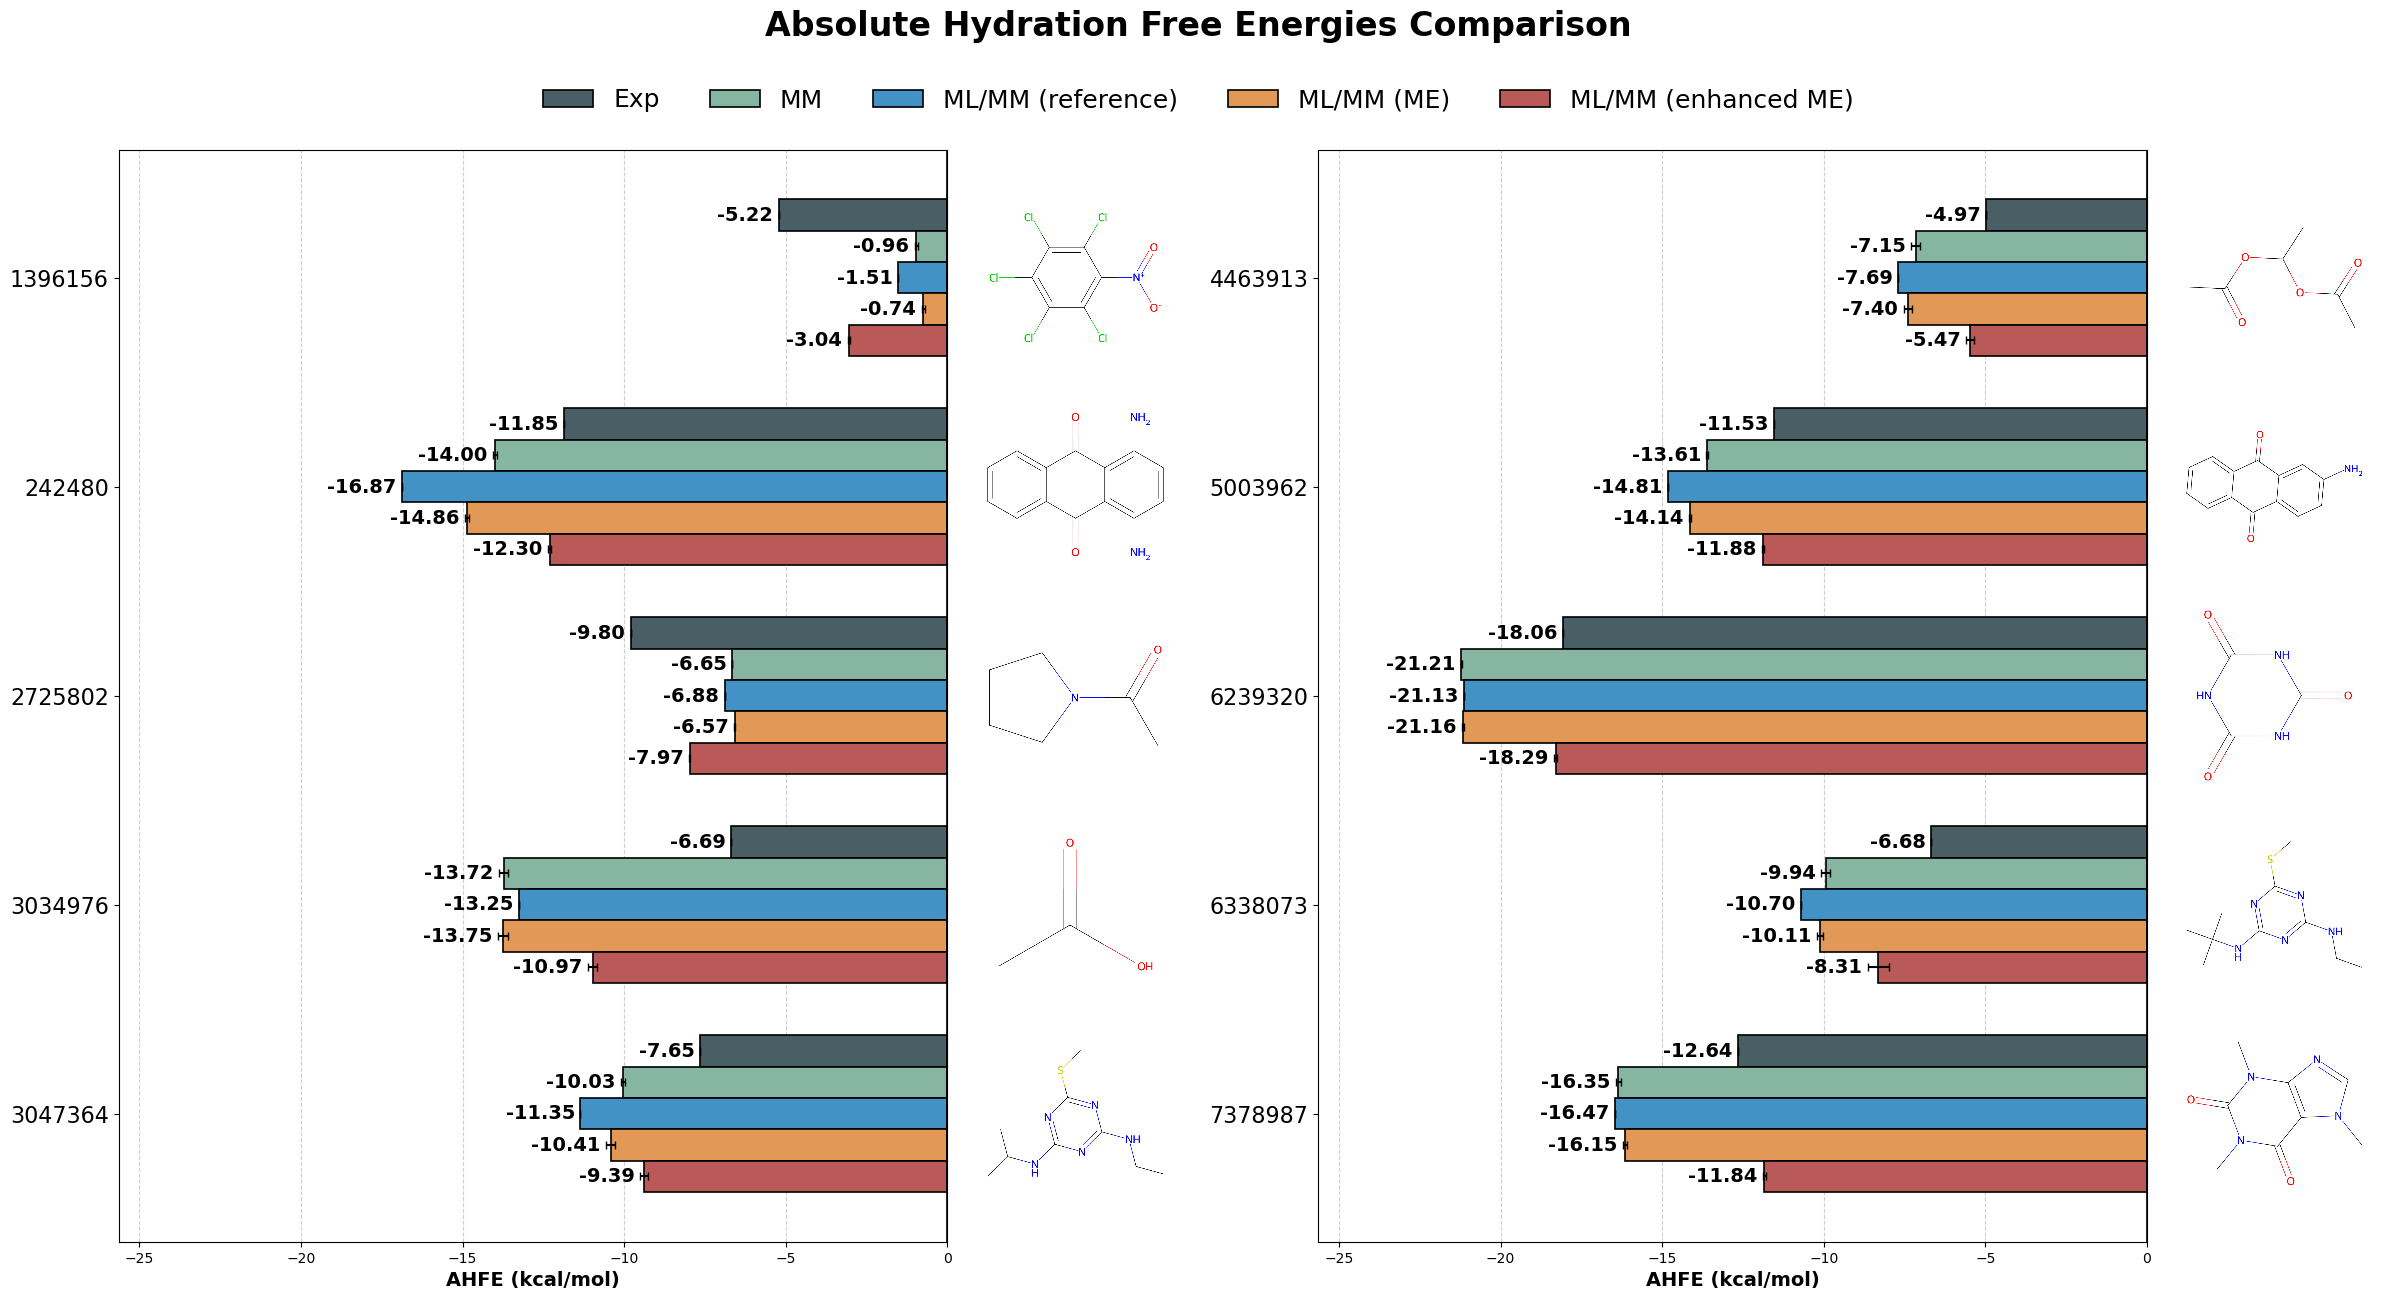

In [ ]:
import matplotlib.gridspec as gridspec
plot_cols = ['exp(kcal/mol)', 'MM (kcal/mol)', 'ML_ref(kcal/mol)', 'ML_ME(kcal/mol)', 'ML_enhancedME (kcal/mol)']

df['mol_id'] = df.index.astype(str).map(lambda x: x.split('_')[0])
df_mean = df.groupby('mol_id')[plot_cols].mean()
df_std = df.groupby('mol_id')[plot_cols].std()
labels = df_mean.index.tolist()

db_path = "./database.txt"
smiles_dict = {}
try:
    with open(db_path, 'r') as f:
        for line in f:
            line = line.strip()
            if not line or line.startswith('#'): continue
            parts = line.split(';') 
            if len(parts) >= 2:
                mid = parts[0].strip()
                smi = parts[1].strip()
                smiles_dict[mid] = smi
except FileNotFoundError:
    pass


fig = plt.figure(figsize=(24, 14))

gs = gridspec.GridSpec(1, 5, width_ratios=[1, 0.22, 0.15, 1, 0.22], wspace=0.05)

ax_bar_L = fig.add_subplot(gs[0])
ax_img_L = fig.add_subplot(gs[1])
ax_bar_R = fig.add_subplot(gs[3], sharex=ax_bar_L) # 共享X轴
ax_img_R = fig.add_subplot(gs[4])

ax_img_L.axis('off')
ax_img_R.axis('off')

width = 0.15
colors = ['#4a5e65', '#86b5a1', '#4292c6', '#e29957', '#b95a58']
bar_labels = ['Exp', 'MM', 'ML/MM (reference)', 'ML/MM (ME)', 'ML/MM (enhanced ME)']

midpoint = len(labels) // 2
groups = [
    (ax_bar_L, ax_img_L, labels[:midpoint], 0),
    (ax_bar_R, ax_img_R, labels[midpoint:], midpoint)
]

for ax_bar, ax_img, ax_labels, offset in groups:
    y_pos = np.arange(len(ax_labels))
    
    # --- A. 绘制数据柱状图 ---
    for i, col in enumerate(plot_cols):
        means = df_mean[col].iloc[offset:offset+len(ax_labels)]
        stds = df_std[col].iloc[offset:offset+len(ax_labels)]
        positions = y_pos + (i - 2) * width
        
        rect = ax_bar.barh(positions, means, height=width, 
                    label=bar_labels[i] if offset==0 else None,
                    xerr=stds, capsize=3, 
                    color=colors[i], edgecolor='black', linewidth=1.2)
        
        ax_bar.bar_label(rect, padding=4, fmt='%.2f', fontsize=14, fontweight='bold')

    ax_bar.set_yticks(y_pos)
    ax_bar.set_yticklabels(ax_labels, fontsize=16) 
    ax_bar.invert_yaxis()  
    
    ax_bar.axvline(0, color='black', linewidth=1.2)
    ax_bar.grid(axis='x', linestyle='--', alpha=0.6)
    ax_bar.set_axisbelow(True)
    ax_bar.set_xlabel('AHFE (kcal/mol)', fontsize=14, fontweight='bold')
    
    ax_img.set_ylim(ax_bar.get_ylim())

    for j, label_id in enumerate(ax_labels):
        lookup_key = label_id
        if f"mobley_{label_id}" in smiles_dict:
            lookup_key = f"mobley_{label_id}"

        if lookup_key in smiles_dict:
            smiles = smiles_dict[lookup_key]
            mol = Chem.MolFromSmiles(smiles)
            if mol:
                img = Draw.MolToImage(mol, size=(700, 700))
                img_arr = np.array(img)
                imagebox = OffsetImage(img_arr, zoom=0.20)
                imagebox.image.axes = ax_img
                
                ab = AnnotationBbox(imagebox, (0.05, y_pos[j]),
                                    xycoords=('axes fraction', 'data'),
                                    boxcoords="offset points",
                                    xybox=(0, 0),
                                    frameon=False, 
                                    box_alignment=(0, 0.5))
                ax_img.add_artist(ab)


xmin, xmax = ax_bar_L.get_xlim()
ax_bar_L.set_xlim(xmin * 1.15, xmax)

# ==========================================
# 4. 全局标题与图例修饰
# ==========================================
fig.suptitle('Absolute Hydration Free Energies Comparison', fontsize=24, fontweight='bold', y=0.96)

handles, labels_leg = ax_bar_L.get_legend_handles_labels()
fig.legend(handles, labels_leg, loc='upper center', bbox_to_anchor=(0.5, 0.92), ncol=5, fontsize=18, frameon=False)

fig.subplots_adjust(top=0.86, bottom=0.08, left=0.05, right=0.98)

plt.savefig('AHFEs_molecules_right_fixed.svg', dpi=300, bbox_inches='tight')
plt.show()